In [ ]:
import sys
print(sys.executable)

# 01 · Data Exploration: Getting to Know the Text

**Project:** One task, three approaches (Chapter 1 of *Practical Natural Language Processing*, O'Reilly 2020)

**The task:** decide whether a movie review is **positive** or **negative** (binary sentiment classification).

Chapter 1 of the book explains that there are three broad ways to solve an NLP problem:

| Approach | Idea | Notebook |
|---|---|---|
| Heuristics (rules) | A human writes the rules, e.g. word lists | `02_heuristic_approach.ipynb` |
| Machine learning | The computer learns weights from labelled examples, using features we design | `03_machine_learning_approach.ipynb` |
| Deep learning | A neural network learns the features *and* the decision, starting from a pre-trained language model | `04_deep_learning_approach.ipynb` |

Before building anything, a good NLP engineer **looks at the data**. In this notebook we answer:
1. How big is the dataset, and how is it split?
2. Are the two classes balanced?
3. How long are the reviews?
4. What does the vocabulary look like (Zipf's law)?
5. Which words are typical for each class?
6. Why is this task harder than it looks? (The book's section *"Why Is NLP Challenging?"*)

## 0. Setup

The helper code shared by all notebooks lives in `src/utils.py`. Python only finds modules in the folders listed in `sys.path`, so we add the **project root** (the folder above `notebooks/`) to that list.

In [9]:
# --- Make the project's `src` folder importable -----------------------------
import sys
from pathlib import Path

# Path.cwd() = the folder Jupyter is running in.
# If we are inside "notebooks/", the project root is one level up (.parent).
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Add the root to Python's search path (only once, even if the cell is re-run).
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project folder:", PROJECT_ROOT.name)   # should print: practical-nlp-ch01-three-approaches

Project folder: practical-nlp-ch01-three-approaches


In [10]:
# --- Standard libraries for data analysis -----------------------------------
from collections import Counter          # counts how often each item appears

import numpy as np                       # numerical computing (arrays, math)
import pandas as pd                      # tables (DataFrames)
import matplotlib.pyplot as plt          # plotting

# Our own helpers (see src/utils.py)
from src.utils import load_imdb, simple_tokenize, LABEL_NAMES, FIGURES_DIR

# Make sure the folder for saved figures exists
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the dataset

We use the dataset the book uses for sentiment classification in Chapter 4: the **IMDB Large Movie Review Dataset** (Maas et al., 2011, Stanford). It contains **50,000 movie reviews** from imdb.com, each labelled positive or negative:
- 25,000 official training reviews and 25,000 official test reviews;
- a review is labelled **negative** if the user's rating was ≤ 4/10 and **positive** if it was ≥ 7/10. Neutral reviews are not included.

The first run downloads the original archive from Stanford (the same link as in the book, about 84 MB) and caches the reviews as CSV files in `data/`. Later runs read the local copy.

**Our splits** (see `load_imdb()` in `src/utils.py`):
- **train:** 90% of the official training reviews (22,500);
- **validation:** the other 10% (2,500), used for all tuning decisions;
- **test:** a fixed, balanced sample of 5,000 of the official test reviews. Every approach is evaluated on exactly these reviews. Using all 25,000 is possible (`EVAL_TEST_SIZE = None`), but makes the deep-learning notebook much slower on a CPU.

In [11]:
# Returns a dictionary: {"train": DataFrame, "validation": DataFrame, "test": DataFrame}
data = load_imdb()

# Print the size of each split
for split_name, df in data.items():
    print(f"{split_name:<11}: {len(df):>6,} reviews")

# Keep short names for the three tables; we will use them a lot.
train, val, test = data["train"], data["validation"], data["test"]

Stanford download failed ([WinError 10054] An existing connection was forcibly closed by the remote host). Trying the mirror ...


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

C:\Users\areft\Projects\practical-nlp-ch01-three-approaches\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\areft\.cache\huggingface\hub\datasets--stanfordnlp--imdb. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\areft\Projects\practical-nlp-ch01-three-approaches\.venv\Lib\site-packages\

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

... (3 outputs left out)

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Saved a local copy to: C:\Users\areft\projects\practical-nlp-ch01-three-approaches\data
train      : 22,500 reviews
validation :  2,500 reviews
test       :  5,000 reviews


**Why three splits?**
- **train**: the examples a model learns from.
- **validation**: used to make choices (thresholds, hyper-parameters) *without* touching the test set.
- **test**: used **once at the very end** to report an honest score. If we tuned on the test set, our score would be too optimistic, because we would be fitting the test data.

In [12]:
def show_review(text: str, label: int, max_chars: int = 400) -> None:
    """Print one review with its label, shortened to max_chars characters."""
    short = text if len(text) <= max_chars else text[:max_chars] + " [...]"
    print(f"[{LABEL_NAMES[label].upper()}] {short}\n")

# Look at a few random training reviews.
# random_state fixes the random choice, so you see the same reviews every time.
for _, row in train.sample(4, random_state=42).iterrows():
    show_review(row["text"], row["label"])

[NEGATIVE] this movie was horrible. I could barely stay awake through it. I would never see this movie again if I were payed to. The so-called horror scenes in it were increadably predictable and over played. There was really nothing about this movie that would have made it original or worth the $7.50 I payed to see it. Don't go see it, don't rent it, don't read about it online because any of these things wo [...]

[POSITIVE] This movie surprised me! Not ever having heard of Hyde of Gackt I was not expecting much! The reason I wanted to watch this movie was because somebody mentioned that the movie contained some serious action scenes in John Woo style! Normally I am very careful when this is claimed! There is only one John Woo and til this day there hasn't been one director that comes close to his brilliance when it c [...]

[POSITIVE] Excellent, pre-code amoral tale with Barbara Stanwyck as the newly inspired (by writings of Nietzsche!) to drive out her sensitivities and exploit hers

**Observations:**
- The reviews are real user texts: **several sentences long**, with normal capitalisation and punctuation, sometimes with typos, slang and CAPITAL LETTERS for emphasis.
- The original files contain HTML line breaks (`<br /><br />`). `load_imdb()` already removed them with `clean_text()`. This is a first example of the *text clean-up* step the book describes in Chapter 2.

## 2. Are the classes balanced?

label
negative    11250
positive    11250
Name: count, dtype: int64

Share of positive reviews: 50.0%


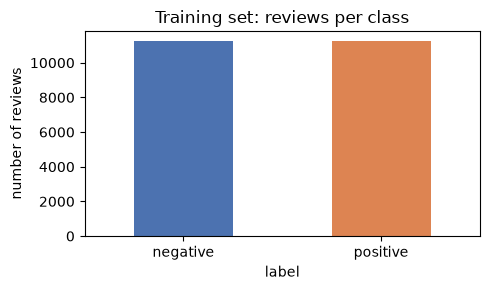

In [13]:
# value_counts() counts how many rows have each label
counts = train["label"].map(LABEL_NAMES).value_counts()
print(counts)
print(f"\nShare of positive reviews: {train['label'].mean():.1%}")

# A simple bar chart
ax = counts.plot(kind="bar", color=["#4C72B0", "#DD8452"], rot=0, figsize=(5, 3))
ax.set_title("Training set: reviews per class")
ax.set_ylabel("number of reviews")
plt.tight_layout()
plt.show()

The classes are perfectly balanced (50/50). This means:
- **accuracy** is a fair metric (it would be misleading if, say, 95% were positive);
- a "dumb" model that always predicts the same class gets **50%**. That is our absolute baseline: every approach must beat it.

## 3. How long are the reviews?

In [14]:
# For every review, count its tokens (roughly: words) with our simple tokenizer.
# .apply(f) runs the function f on every value of the column.
train["n_tokens"] = train["text"].apply(lambda t: len(simple_tokenize(t)))

# describe() gives count, mean, std, min, quartiles and max, per class
train.groupby(train["label"].map(LABEL_NAMES))["n_tokens"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
negative,11250.0,231.2,167.0,10.0,128.0,175.0,279.0,1522.0
positive,11250.0,236.3,179.6,12.0,126.0,175.0,289.0,2473.0


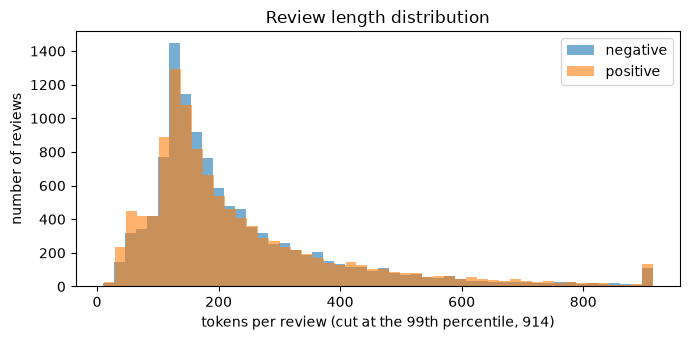

In [15]:
# Histogram of review lengths, one colour per class.
# A few reviews are extremely long, so we cut the x-axis at the 99th percentile
# to keep the plot readable.
upper = np.percentile(train["n_tokens"], 99)
fig, ax = plt.subplots(figsize=(7, 3.5))
for label, name in LABEL_NAMES.items():
    lengths = train.loc[train["label"] == label, "n_tokens"]
    ax.hist(lengths.clip(upper=upper), bins=50, alpha=0.6, label=name)   # alpha = transparency
ax.set_xlabel(f"tokens per review (cut at the 99th percentile, {upper:.0f})")
ax.set_ylabel("number of reviews")
ax.set_title("Review length distribution")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "review_lengths.png", dpi=120)
plt.show()

Reviews are typically a few hundred words long, with a long right tail, and both classes have similar length distributions. So **length alone tells us little about sentiment**.

The length matters for the deep-learning notebook: transformer models such as DistilBERT can read at most **512 tokens**, and their cost grows with the *square* of the input length. We will have to cut long reviews (see notebook 04).

## 4. The vocabulary and Zipf's law

**Zipf's law** says that in natural language, the frequency of a word is roughly inversely proportional to its rank:

$$ f(r) \approx \frac{C}{r^{s}} \quad\Longrightarrow\quad \log f(r) \approx \log C - s \cdot \log r, \qquad s \approx 1 $$

So on a log-log plot, rank vs. frequency should look like a **straight line with slope ≈ −1**. This is why NLP always has to handle a *long tail* of rare words.

In [16]:
# Count every token in the whole training set.
# Counter.update(list) adds the items of the list to the counts.
word_counts = Counter()
for review in train["text"]:
    word_counts.update(simple_tokenize(review))

print(f"Total tokens      : {sum(word_counts.values()):,}")
print(f"Vocabulary size   : {len(word_counts):,} different words")

# How many words appear only once? These are called "hapax legomena".
hapax = sum(1 for c in word_counts.values() if c == 1)
print(f"Words seen once   : {hapax:,} ({hapax / len(word_counts):.0%} of the vocabulary)")

print("\n15 most common tokens:")
print(word_counts.most_common(15))

Total tokens      : 5,258,512
Vocabulary size   : 77,728 different words
Words seen once   : 29,854 (38% of the vocabulary)

15 most common tokens:
[('the', 302865), ('and', 147882), ('a', 147048), ('of', 131562), ('to', 122053), ('is', 96683), ('in', 84411), ('it', 71332), ('i', 69534), ('this', 68625), ('that', 62804), ('was', 43349), ('as', 42320), ('for', 39845), ('with', 39686)]


Fitted Zipf exponent s = 1.60  (the theory predicts about 1)


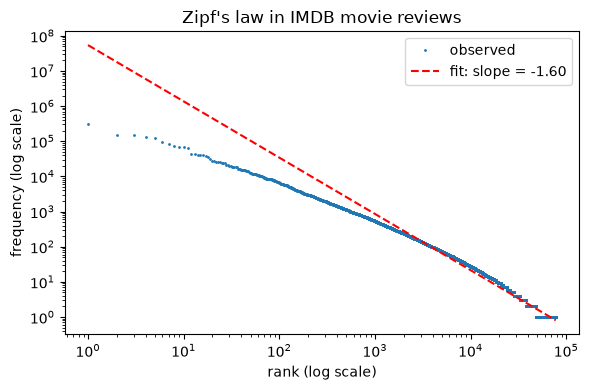

In [17]:
# Sort the frequencies from largest to smallest; the position in this list is the rank.
freqs = np.array(sorted(word_counts.values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)

# Fit a straight line to log(frequency) vs log(rank) with least squares.
# np.polyfit(x, y, 1) returns [slope, intercept] of the best line y = slope*x + intercept.
slope, intercept = np.polyfit(np.log(ranks), np.log(freqs), deg=1)
print(f"Fitted Zipf exponent s = {-slope:.2f}  (the theory predicts about 1)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(ranks, freqs, ".", markersize=2, label="observed")
ax.loglog(ranks, np.exp(intercept) * ranks**slope, "r--", label=f"fit: slope = {slope:.2f}")
ax.set_xlabel("rank (log scale)")
ax.set_ylabel("frequency (log scale)")
ax.set_title("Zipf's law in IMDB movie reviews")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "zipf_law.png", dpi=120)
plt.show()

A large share of the vocabulary consists of words that appear only once: names, typos, rare words. Any approach based on fixed word lists (heuristics) or on counting words (classic ML) will meet many words it has never seen before. Pre-trained deep-learning models handle this better, because they split unknown words into known sub-word pieces (we will see this in notebook 04).

## 5. Which words are typical for each class?

Simply counting the most common words is not useful, because words like *the* and *a* dominate both classes. Instead, we compute the **log-odds ratio** of each word:

$$ \text{score}(w) = \log \frac{P(w \mid \text{positive})}{P(w \mid \text{negative})} $$

A large positive score means the word appears much more often in positive reviews. We add 1 to every count (**Laplace smoothing**) so that a word seen in only one class does not give a division by zero.

In [18]:
# Count words separately for each class
pos_counts, neg_counts = Counter(), Counter()
for text, label in zip(train["text"], train["label"]):
    tokens = simple_tokenize(text)
    (pos_counts if label == 1 else neg_counts).update(tokens)

total_pos = sum(pos_counts.values())
total_neg = sum(neg_counts.values())
vocab = set(pos_counts) | set(neg_counts)       # union of both vocabularies

rows = []
for w in vocab:
    n_pos, n_neg = pos_counts[w], neg_counts[w]
    if n_pos + n_neg < 50:                       # ignore rare words: their scores are noisy
        continue
    p_pos = (n_pos + 1) / (total_pos + len(vocab))   # smoothed P(w | positive)
    p_neg = (n_neg + 1) / (total_neg + len(vocab))   # smoothed P(w | negative)
    rows.append({"word": w, "n_pos": n_pos, "n_neg": n_neg, "log_odds": np.log(p_pos / p_neg)})

log_odds = pd.DataFrame(rows).sort_values("log_odds")

print("Most NEGATIVE words:")
display(log_odds.head(15).reset_index(drop=True))
print("Most POSITIVE words:")
display(log_odds.tail(15).iloc[::-1].reset_index(drop=True))

Most NEGATIVE words:


,word,n_pos,n_neg,log_odds
0,boll,0,116,-4.783303
1,uwe,0,90,-4.531989
2,stinker,2,92,-3.455116
3,seagal,3,120,-3.430625
4,beowulf,1,54,-3.335315
5,gadget,3,75,-2.965568
6,unwatchable,4,94,-2.965568
7,gamera,2,54,-2.929850
8,dreck,3,71,-2.911501
9,mst3k,6,121,-2.879240


Most POSITIVE words:


,word,n_pos,n_neg,log_odds
0,edie,93,0,4.522166
1,din,64,0,4.153258
2,gypo,54,0,3.986204
3,gunga,50,0,3.910697
4,paulie,91,1,3.807512
5,sox,52,1,3.256016
6,gundam,75,2,3.210992
7,kolchak,67,2,3.099766
8,felix,84,3,3.035228
9,polanski,78,3,2.962024


Compare these lists with the words *you* would write down as sentiment words. Some will match your expectations; others will be words a human would not think of as sentiment words, but which still separate the classes in *this* data (for example, words that people use when they rate a film very low or very high). A machine-learning model learns such patterns automatically. A human-written rule list misses them.

## 6. Why is NLP challenging? Examples from our data

Chapter 1 names several reasons: **ambiguity**, **common knowledge** (things people know but never write down), **creativity** (sarcasm, irony, metaphors) and **diversity across languages**. Let's look for some of them in our data.

In [19]:
def show_examples(mask, n=3, title=""):
    """Print n example reviews selected by a True/False mask, with their labels."""
    subset = train[mask].sample(min(n, int(mask.sum())), random_state=0)
    print(f"--- {title} ({int(mask.sum()):,} reviews in total) ---\n")
    for text, label in zip(subset["text"], subset["label"]):
        show_review(text, label, max_chars=300)

tokens_per_review = train["text"].apply(lambda t: set(simple_tokenize(t)))

# 1) A strongly "positive" word in a NEGATIVE review
show_examples(tokens_per_review.apply(lambda s: "brilliant" in s) & (train["label"] == 0),
              title="Contains 'brilliant' but is NEGATIVE")

# 2) A strongly "negative" word in a POSITIVE review
show_examples(tokens_per_review.apply(lambda s: "awful" in s) & (train["label"] == 1),
              title="Contains 'awful' but is POSITIVE")

--- Contains 'brilliant' but is NEGATIVE (229 reviews in total) ---

[NEGATIVE] This is one of the worst film adaptations of a musical ever made. The stage version of A Chorus Line is wonderful. This movie misses the mark in almost every way. Even the casting is baffling. Take Audrey Landers as Val. "Dance 10 Looks 3" is Val's song. Val's story is that she is a great dancer but [...]

[NEGATIVE] Around the late 1970's, animator Don Bluth, frustrated with the output his company, Disney was churning, defected from the Mouse House to form his own studio. His first production, THE SECRET OF NIMH, was a brilliant feature that still holds up well to this day. This was followed by AN American TAIL [...]

[NEGATIVE] Anyone who has seen 'Shine',Scott Hicks film of the heartbreaking yet ultimately joyful life of the pianist David Helfgotts; will I am sure realise that 'The SOLOIST' is very poor in comparison.It is as slow as a lullaby( I took five breaks answering emails just to wake up). The de

Read a few of these examples. They show why simple word counting is not enough:
- **Negation** flips the meaning: *"not brilliant"*, *"never boring"*.
- **Contrast and mixed opinions**: *"the acting is brilliant, but the story is a mess"*. In long reviews this is common: the reviewer discusses good *and* bad aspects, and the overall verdict often comes at the end.
- **Quotes and context**: a reviewer may quote other people (*"critics called it brilliant"*) or describe the *content* of the film (*"an awful villain"*) rather than give their opinion.
- **Irony and world knowledge**: some opinions are only clear if you understand the joke.

We will see how each of the three approaches handles these difficulties.

## Summary

- 50,000 real IMDB reviews; we use 22,500 for training, 2,500 for validation and a fixed sample of 5,000 for testing.
- Perfectly balanced classes, so the baseline to beat is **50% accuracy**.
- Reviews are long (a few hundred words), which matters for the deep-learning model's input limit.
- The vocabulary follows **Zipf's law**: a few very frequent words and a long tail of rare ones.
- Many words carry sentiment, but **negation, contrast, quotes and irony** make the task hard.

**Next:** `02_heuristic_approach.ipynb`, solving the task with hand-written rules, without any training data.